# Slide 9 — Non-deployable beds hide the real BOR

This notebook rebuilds the slide 9 chart (**BOR 2022 by specialty**) and the three headline numbers (**87%**, **~32%**, **~95%**) from the case spreadsheet `119SMU-XLS-ENG.xlsx`.

**Formula used:** BOR = patient days ÷ (average beds in service × 365)

- *Patient days* come from the sheet **Patient Days by Speciality** (the “2022 Total” column of each specialty’s *Total* row).
- *Average beds* come from the sheet **Monthly Ave Beds Available** (right-hand table, 2022 column).
- *Non-deployable* beds come from the same sheet’s left-hand table (rows whose *Comments* say “Non-deployable”).

The only assumption is in Step 6 (how full non-deployable beds are) and it is a setting you can change.

## Step 1 — Settings
Put the Excel file next to this notebook (or in Google Drive when using Colab) and set `FILE`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- Google Colab: uncomment the next two lines and use the Drive path below ---
# from google.colab import drive
# drive.mount('/content/drive')
# FILE = "/content/drive/MyDrive/Colab Notebooks/119SMU-XLS-ENG.xlsx"

FILE = "119SMU-XLS-ENG.xlsx"     # file in the same folder as this notebook
YEAR = 2022
DAYS = 366 if YEAR == 2020 else 365
MOH_LIMIT = 0.85
OUT = "slide9_BOR_by_specialty_2022.png"
print("Using:", os.path.abspath(FILE))

Using: /home/claude/s9/run/119SMU-XLS-ENG.xlsx


## Step 2 — Patient days per specialty
Each specialty block ends with a row called “<Specialty> Total”. We take that row’s value in the “2022 Total” column.

In [2]:
pdays_raw = pd.read_excel(FILE, sheet_name="Patient Days by Speciality", header=None)
header = pdays_raw.iloc[2].astype(str).str.strip()            # row with '2018', '2018 Total', ...
col = header[header == f"{YEAR} Total"].index[0]

totals = pdays_raw[pdays_raw[0].astype(str).str.endswith(" Total")]
totals = totals[totals[0] != "Grand Total"]
pdays = pd.DataFrame({
    "Specialty": totals[0].str.replace(" Total", "", regex=False).str.strip(),
    "PatientDays": pd.to_numeric(totals[col]),
})
grand = pd.to_numeric(pdays_raw.loc[pdays_raw[0] == "Grand Total", col]).iloc[0]
print(len(pdays), "specialties; total patient days", f"{pdays.PatientDays.sum():,.0f}", "| sheet Grand Total", f"{grand:,.0f}")
assert pdays.PatientDays.sum() == grand
pdays.head()

27 specialties; total patient days 542,305 | sheet Grand Total 542,305


,Specialty,PatientDays
9,Burns,1710
15,Colorectal Surgery,9888
21,Endocrinology,1811
27,Gastroenterology,12984
33,General Surgery,64564


## Step 3 — Average beds per specialty, and how many are non-deployable

In [3]:
beds_raw = pd.read_excel(FILE, sheet_name="Monthly Ave Beds Available", header=None)

# right-hand table: one row per specialty (name, code, 2018..2022)
right = beds_raw.iloc[2:, 10:17].copy()
right.columns = ["Specialty", "Code", 2018, 2019, 2020, 2021, 2022]
right = right[right["Code"].notna() & (right["Specialty"] != "Grand Total")]
beds = right[["Specialty", "Code", YEAR]].rename(columns={YEAR: "Beds"})
beds["Beds"] = pd.to_numeric(beds["Beds"])

# left-hand table: one row per specialty x ward type, with a 'Non-deployable' comment
left = beds_raw.iloc[2:, 1:9].copy()
left.columns = ["Code", "Ward", 2018, 2019, 2020, 2021, 2022, "Comment"]
left = left[left["Ward"].notna() & left["Code"].isin(beds["Code"])]
left[YEAR] = pd.to_numeric(left[YEAR])
nd = (left[left["Comment"].astype(str).str.strip() == "Non-deployable"]
      .groupby("Code")[YEAR].sum().rename("NonDeployBeds"))
beds = beds.merge(nd, on="Code", how="left").fillna({"NonDeployBeds": 0})
beds["NonDeployShare"] = beds["NonDeployBeds"] / beds["Beds"]
print(f"Total beds {beds.Beds.sum():,.2f}; non-deployable {beds.NonDeployBeds.sum():,.2f}")
beds.head()

Total beds 1,713.83; non-deployable 550.33


,Specialty,Code,Beds,NonDeployBeds,NonDeployShare
0,Burns,GBNS,28.083333,28.083333,1.000000
1,Colorectal Surgery,GCLR,53.833333,8.000000,0.148607
2,Internal Medicine,GDIM,370.583333,3.000000,0.008095
3,Endocrinology,GEND,15.000000,0.000000,0.000000
4,Otorhinolaryngology,GENT,32.750000,5.750000,0.175573


## Step 4 — BOR by specialty
Names are matched case-insensitively (the two sheets write *General Surgery* / *General surgery*).

In [4]:
df = pdays.assign(key=pdays.Specialty.str.lower()).merge(
        beds.assign(key=beds.Specialty.str.lower()).drop(columns="Specialty"), on="key", how="outer", indicator=True)
assert (df["_merge"] == "both").all(), df[df["_merge"] != "both"]
df = df.drop(columns=["key", "_merge"])
df["BOR"] = df.PatientDays / (df.Beds * DAYS)
df["Hatched"] = df.NonDeployShare >= 0.5             # 50%+ of the specialty's beds are non-deployable
df["Label"] = df.Specialty.replace({"Otorhinolaryngology": "ENT (Otorhinolaryngology)"})
df = df.sort_values("BOR", ascending=False).reset_index(drop=True)
df[["Label", "PatientDays", "Beds", "NonDeployShare", "BOR"]].style.format(
    {"PatientDays": "{:,.0f}", "Beds": "{:.2f}", "NonDeployShare": "{:.0%}", "BOR": "{:.0%}"})

,Label,PatientDays,Beds,NonDeployShare,BOR
0,Rheumatology,"3,835",4.00,0%,263%
1,Medical Oncology,"57,746",79.67,100%,199%
2,Haematology,"27,730",60.08,100%,126%
3,Neurosurgery,"13,641",31.00,42%,121%
4,Internal Medicine,"158,602",370.58,1%,117%
5,Neurology,"23,676",57.00,26%,114%
6,Geriatric Medicine,"9,975",25.00,0%,109%
7,Renal Medicine,"36,426",98.42,100%,101%
8,General Surgery,"64,564",194.17,0%,91%
9,Gastroenterology,"12,984",40.00,0%,89%


## Step 5 — The chart

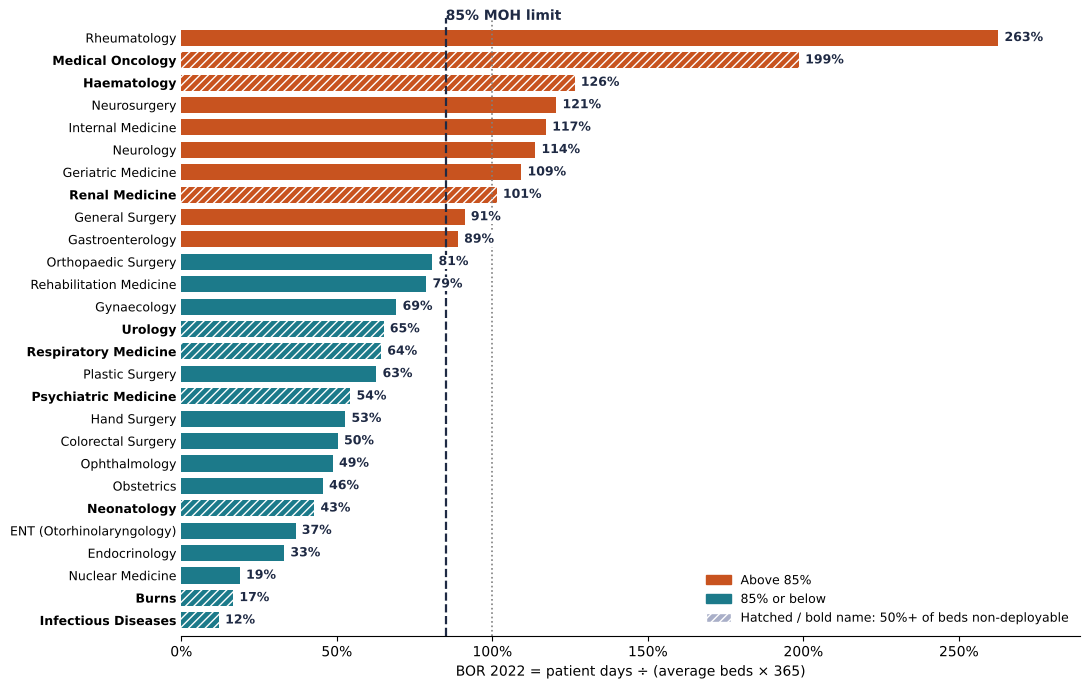

Saved slide9_BOR_by_specialty_2022.png


In [5]:
ORANGE, TEAL, INK = "#C8531F", "#1C7A8A", "#1F2A44"
plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(df))[::-1]                      # highest BOR at the top
colors = [ORANGE if b > MOH_LIMIT else TEAL for b in df.BOR]
bars = ax.barh(y, df.BOR * 100, color=colors, height=0.72,
               hatch=["////" if h else "" for h in df.Hatched], edgecolor="white", linewidth=0)

for yi, b in zip(y, df.BOR):                       # value labels
    ax.text(b * 100 + 2, yi, f"{b:.0%}", va="center", fontsize=9, fontweight="bold", color=INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.6), zorder=5)

ax.set_yticks(y)
ax.set_yticklabels(df.Label, fontsize=9)
for tick, h in zip(ax.get_yticklabels(), df.Hatched):
    tick.set_fontweight("bold" if h else "normal")

ax.axvline(MOH_LIMIT * 100, color=INK, linestyle="--", linewidth=1.6)
ax.axvline(100, color="grey", linestyle=":", linewidth=1.2)
ax.text(MOH_LIMIT * 100, len(df) - 0.2, "85% MOH limit", fontsize=10, fontweight="bold", color=INK)

ax.set_xlim(0, max(df.BOR) * 100 * 1.1)
ax.set_ylim(-0.7, len(df) - 0.1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel(f"BOR {YEAR} = patient days ÷ (average beds × {DAYS})", fontsize=10)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

ax.legend(handles=[Patch(color=ORANGE, label="Above 85%"),
                   Patch(color=TEAL, label="85% or below"),
                   Patch(facecolor="#A9AFC8", hatch="////", edgecolor="white",
                         label="Hatched / bold name: 50%+ of beds non-deployable")],
          loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(OUT, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved", OUT)

## Step 6 — The three headline numbers on slide 9

- **Blended BOR**: all patient days ÷ (all beds × 365).
- **Non-deployable share**: non-deployable beds ÷ all beds.
- **Implied BOR on deployable beds**: this needs one assumption — how full the non-deployable beds are. The slide uses **70%**; change `ND_OCCUPANCY` to test other values.

In [6]:
ND_OCCUPANCY = 0.70        # assumption used on the slide

total_pd   = df.PatientDays.sum()
total_beds = df.Beds.sum()
nd_beds    = df.NonDeployBeds.sum()
dep_beds   = total_beds - nd_beds

blended   = total_pd / (total_beds * DAYS)
nd_share  = nd_beds / total_beds
pd_on_nd  = ND_OCCUPANCY * nd_beds * DAYS           # patient days assumed to sit in non-deployable beds
dep_bor   = (total_pd - pd_on_nd) / (dep_beds * DAYS)

print(f"Blended BOR {YEAR}:            {total_pd:,.0f} ÷ ({total_beds:,.0f} × {DAYS}) = {blended:.1%}")
print(f"Non-deployable share:        {nd_beds:,.0f} of {total_beds:,.0f} beds = {nd_share:.1%}")
print(f"Implied deployable BOR:      {dep_bor:.1%}  (assumes non-deployable beds {ND_OCCUPANCY:.0%} full)")

print("\nSensitivity of the deployable BOR to the assumption:")
for occ in (0.5, 0.6, 0.7, 0.8, 0.9):
    v = (total_pd - occ * nd_beds * DAYS) / (dep_beds * DAYS)
    print(f"  non-deployable {occ:.0%} full  ->  deployable BOR {v:.1%}")

Blended BOR 2022:            542,305 ÷ (1,714 × 365) = 86.7%
Non-deployable share:        550 of 1,714 beds = 32.1%
Implied deployable BOR:      94.6%  (assumes non-deployable beds 70% full)

Sensitivity of the deployable BOR to the assumption:
  non-deployable 50% full  ->  deployable BOR 104.0%
  non-deployable 60% full  ->  deployable BOR 99.3%
  non-deployable 70% full  ->  deployable BOR 94.6%
  non-deployable 80% full  ->  deployable BOR 89.9%
  non-deployable 90% full  ->  deployable BOR 85.1%


## Notes and limits
- Beds are **average licensed beds in service** for the year, so a specialty can exceed 100% when its patients stay in other specialties’ wards (e.g. Medical Oncology).
- “Non-deployable” follows the spreadsheet’s *Comments* column.
- The deployable-BOR figure depends entirely on the assumed occupancy of non-deployable beds; the spreadsheet does not record where each patient day was spent.